# Approche 2 : les sessions comme des textes (TF-IDF)

- Le notebook 2 plafonne à **0,942 de F1 macro** (ExtraTrees sur 756 features manuelles, tout le vocabulaire).
- Ici, chaque session devient un **document** et ses actions des **mots** : c'est le problème classique de l'attribution d'auteur.
- On justifie d'abord la représentation, on choisit les jetons, puis on teste les modèles (un par cellule), avec et sans la **contrainte « même navigateur »**.
- La dernière cellule génère la soumission du modèle choisi : LinearSVC `C=30` + contrainte : **0,988 sur Kaggle**, exactement comme `C=3`.

Explication détaillée sur une vraie session : `explication_tfidf.md`.

## 1. Chargement des données

In [2]:
import os
import re
import time
import unicodedata
from collections import Counter

import logging

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)  # avertissements de police
MARQUEUR = re.compile(r"t\d+")

def lire_sessions(chemin, avec_label):
    """Une ligne par session : utilisateur (train seulement), navigateur, actions, durée (dernier marqueur tXX)."""
    lignes = []
    with open(chemin, encoding="utf-8") as f:
        for ligne in f:
            champs = ligne.rstrip("\n").split(",")
            util = champs.pop(0) if avec_label else None
            marqueurs = [int(e[1:]) for e in champs[1:] if MARQUEUR.fullmatch(e)]
            actions = [e for e in champs[1:] if not MARQUEUR.fullmatch(e)]
            lignes.append({"util": util, "navigateur": champs[0], "actions": actions,
                           "nb_actions": len(actions), "duree": marqueurs[-1] if marqueurs else 0})
    return pd.DataFrame(lignes)

train = lire_sessions("data/train.csv", avec_label=True)
test = lire_sessions("data/test.csv", avec_label=False)

# valeurs aberrantes (cf. 1_exploration) : on retire du train les sessions de moins de 10 actions, jamais du test
train = train[train["nb_actions"] >= 10].reset_index(drop=True)
utilisateurs = pd.Categorical(train["util"])
classes, y = utilisateurs.categories, utilisateurs.codes
K = len(classes)
print(len(train), "sessions d'entraînement,", len(test), "sessions de test,", K, "utilisateurs")

3276 sessions d'entraînement, 324 sessions de test, 247 utilisateurs


In [3]:
P_ECRAN, P_CONF, P_CHAINE = re.compile(r"\((.*?)\)"), re.compile(r"<(.*?)>"), re.compile(r"\$(.*?)\$")

def type_action(action):
    """Texte avant l'écran, la configuration et la chaîne, sans le '1' final de modification."""
    t = re.split(r"[(<$]", action)[0]
    return t[:-1] if t.endswith("1") else t

def contexte(action):
    """(écran, configuration, chaîne) de l'action, None si absent."""
    return tuple(m.group(1) if (m := p.search(action)) else None for p in (P_ECRAN, P_CONF, P_CHAINE))

## 2. Pourquoi une représentation textuelle ?

Le notebook 2 donne déjà à l'ExtraTrees **tout le vocabulaire**, valeurs rares comprises. Certaines sont de vraies **signatures**, utilisées par un seul utilisateur :

In [4]:
for famille, position in (("ecran", 0), ("conf", 1)):
    utilisateurs_par_valeur, sessions_par_valeur = {}, Counter()
    for actions, u in zip(train["actions"], train["util"]):
        for v in {contexte(a)[position] for a in actions} - {None}:
            utilisateurs_par_valeur.setdefault(v, set()).add(u)
            sessions_par_valeur[v] += 1
    signatures = {v for v, us in utilisateurs_par_valeur.items() if len(us) == 1 and sessions_par_valeur[v] >= 2}
    print(f"{famille:6s}: {len(utilisateurs_par_valeur)} valeurs, dont {len(signatures)} propres à un seul utilisateur "
          f"(vues dans au moins 2 sessions)")

ecran : 418 valeurs, dont 32 propres à un seul utilisateur (vues dans au moins 2 sessions)
conf  : 219 valeurs, dont 20 propres à un seul utilisateur (vues dans au moins 2 sessions)


- Ces signatures sont des colonnes du notebook 2, et pourtant l'ExtraTrees plafonne à 0,942 : **avoir l'information ne suffit pas, il faut la représenter autrement**.
- Dans les features manuelles, chaque famille est comptée à part : rien ne relie un geste à l'écran où il est fait, ni une action à la suivante. Et pour un arbre, une colonne rare est une colonne comme une autre, nulle presque partout.

**Ce que la TF-IDF apporte**
- **IDF** : un jeton rare dans le train (un écran que peu de gens ouvrent) pèse beaucoup plus qu'un jeton que tout le monde produit (« Exécution d'un bouton »).
- **TF sous-linéaire** (`1 + ln(compte)`) et **normalisation** du vecteur : une session courte et une longue d'un même utilisateur restent comparables (c'était le rôle des fréquences relatives).
- **Combinaisons et enchaînements gratuits** : l'action complète combine type, écran, configuration et chaîne, et les bigrammes captent les habitudes d'enchaînement.
- Des dizaines de milliers de colonnes creuses : c'est le terrain des **modèles linéaires**.

## 3. Les jetons d'une session

Plusieurs « vues » de chaque action, préfixées pour ne pas se mélanger :

| Jeton | Ce qu'il capte |
|---|---|
| action complète | le geste précis, à l'endroit précis |
| bigramme d'actions (`a >> b`) | une habitude d'enchaînement |
| `T=` type seul, `T2=` bigramme de types | le geste, où qu'il soit fait |
| `E=` écran, `C=` configuration, `H=` chaîne | l'endroit, quel que soit le geste |
| `NAV=` navigateur | le navigateur |

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer

def ngrammes(seq, n):
    return [" >> ".join(seq[i:i + n]) for i in range(len(seq) - n + 1)]

def jetons_session(navigateur, actions, vues_multiples=True, trigrammes=False):
    jetons = ["NAV=" + navigateur] + actions + ngrammes(actions, 2)
    if trigrammes:
        jetons += ngrammes(actions, 3)
    if vues_multiples:
        types = [type_action(a) for a in actions]
        jetons += ["T=" + t for t in types] + ["T2=" + b for b in ngrammes(types, 2)]
        for a in actions:
            for prefixe, valeur in zip(("E=", "C=", "H="), contexte(a)):
                if valeur is not None:
                    jetons.append(prefixe + valeur)
    return jetons

def vectoriseur():
    # sublinear_tf : 1 + log du compte ; min_df=2 : jetons vus dans au moins 2 sessions
    return TfidfVectorizer(analyzer=lambda doc: doc, sublinear_tf=True, min_df=2)

docs_train = [jetons_session(n, a) for n, a in zip(train["navigateur"], train["actions"])]
docs_test = [jetons_session(n, a) for n, a in zip(test["navigateur"], test["actions"])]
tfidf = vectoriseur().fit(docs_train)
print(len(tfidf.vocabulary_), "jetons distincts dans le vocabulaire")

46666 jetons distincts dans le vocabulaire


### Exemple : les poids d'une session de `slq`

Session de 32 actions, déjà suivie dans `explication_tfidf.md`.

In [6]:
i = train.index[(train["util"] == "slq") & (train["nb_actions"] == 32)][0]
vecteur = tfidf.transform([docs_train[i]])
noms_jetons = tfidf.get_feature_names_out()
nb_sessions_avec = np.bincount(tfidf.transform(docs_train).nonzero()[1], minlength=len(noms_jetons))
comptes = Counter(docs_train[i])

exemple = pd.DataFrame({"jeton": [noms_jetons[j][:80] for j in vecteur.indices],
                        "compte": [comptes[noms_jetons[j]] for j in vecteur.indices],
                        "sessions qui le contiennent": nb_sessions_avec[vecteur.indices],
                        "poids TF-IDF": vecteur.data}).sort_values("poids TF-IDF", ascending=False)
pd.concat([exemple.head(5), exemple.sort_values("compte", ascending=False).head(3)]).round(3)

,jeton,compte,sessions qui le contiennent,poids TF-IDF
13,Exécution d'un bouton >> Saisie dans un champ(...,1,4,0.262
2,E=fr.infologic.achatsventes.client.modules.fic...,1,6,0.250
26,Saisie dans un champ(fr.infologic.achatsventes...,1,6,0.250
11,Exécution d'un bouton >> Raccourci(fr.infologi...,1,11,0.231
21,Raccourci(fr.infologic.ventes.client.modules.c...,1,12,0.228
43,T=Exécution d'un bouton,14,3275,0.127
7,Exécution d'un bouton,14,3232,0.129
47,T=Saisie dans un champ,12,3206,0.124


- « Exécution d'un bouton » apparaît 14 fois mais pèse **deux fois moins** que l'écran `FicheRefForm`, vu une seule fois : tout le monde clique sur des boutons, très peu de gens ouvrent cet écran.
- Cet écran n'apparaît que dans 6 sessions du train : à lui seul, il réduit fortement les candidats.

## 4. Validation croisée et contrainte « même navigateur »

- Même protocole que le notebook 2 : 4 plis stratifiés, même découpage. Le vectoriseur est **dans le pipeline** : vocabulaire et IDF sont appris sur les plis d'entraînement seulement (pas de fuite).
- Chaque utilisateur n'utilise qu'**un seul navigateur** (vrai pour les 247, cf. `1_exploration`). Le modèle ne voit le navigateur que comme un jeton parmi des milliers ; la **contrainte** impose la règle : on prédit le meilleur score **parmi les utilisateurs du navigateur de la session**.
- Pour chaque modèle, on mesure donc les deux : sans et avec contrainte.

In [7]:
from sklearn.base import clone
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(n_splits=4, shuffle=True, random_state=0)
nav_classe = train.groupby(y)["navigateur"].first().reindex(range(K)).to_numpy(dtype=object)
documents = {"vues multiples": (docs_train, docs_test)}   # jeux de jetons, complétés en section 5
modeles, resultats, scores_oof = {}, {}, {}

def scores_classes(modele, docs):
    """Score de chaque utilisateur : decision_function pour les SVM, probabilités pour les arbres."""
    s = modele.decision_function(docs) if hasattr(modele, "decision_function") else modele.predict_proba(docs)
    scores = np.full((len(docs), K), -np.inf)
    scores[:, modele.classes_] = s
    return scores

def appliquer_contrainte(scores, navs):
    compatibles = nav_classe[None, :] == np.asarray(navs, dtype=object)[:, None]
    return np.where(compatibles, scores, -np.inf).argmax(axis=1)

def evaluer(nom, modele, jetons="vues multiples"):
    """Scores hors-pli sur le train ; F1 sans et avec contrainte enregistrés dans `resultats`."""
    debut, docs = time.time(), documents[jetons][0]
    scores = np.full((len(y), K), -np.inf)
    for tr, va in skf.split(docs, y):
        m = clone(modele).fit([docs[i] for i in tr], y[tr])
        scores[va] = scores_classes(m, [docs[i] for i in va])
    libre, contraint = scores.argmax(axis=1), appliquer_contrainte(scores, train["navigateur"])
    modeles[nom], scores_oof[nom] = (modele, jetons), scores
    resultats[nom] = {"accuracy": accuracy_score(y, libre), "F1 macro": f1_score(y, libre, average="macro"),
                      "accuracy (contrainte)": accuracy_score(y, contraint),
                      "F1 macro (contrainte)": f1_score(y, contraint, average="macro"),
                      "durée (s)": time.time() - debut}
    r = resultats[nom]
    print(f"{nom} : F1 macro={r['F1 macro']:.3f}, avec contrainte={r['F1 macro (contrainte)']:.3f}  "
          f"({r['durée (s)']:.0f} s)")

## 5. Choix des jetons

Avec le même modèle (LinearSVC, `C=3`), on compare quatre jeux de jetons.

In [8]:
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC, LinearSVC

variantes = {"actions + bigrammes": dict(vues_multiples=False),
             "actions + bigrammes + trigrammes": dict(vues_multiples=False, trigrammes=True),
             "vues multiples + trigrammes": dict(trigrammes=True)}
for jetons, options in variantes.items():
    documents[jetons] = tuple([jetons_session(n, a, **options) for n, a in zip(df["navigateur"], df["actions"])]
                              for df in (train, test))

for jetons in ["actions + bigrammes", "actions + bigrammes + trigrammes", "vues multiples", "vues multiples + trigrammes"]:
    evaluer(f"LinearSVC C=3 [{jetons}]", make_pipeline(vectoriseur(), LinearSVC(C=3)), jetons)

LinearSVC C=3 [actions + bigrammes] : F1 macro=0.946, avec contrainte=0.965  (17 s)
LinearSVC C=3 [actions + bigrammes + trigrammes] : F1 macro=0.938, avec contrainte=0.962  (42 s)
LinearSVC C=3 [vues multiples] : F1 macro=0.949, avec contrainte=0.967  (26 s)
LinearSVC C=3 [vues multiples + trigrammes] : F1 macro=0.946, avec contrainte=0.965  (51 s)


- Les **vues multiples** (type, écran, configuration, chaîne séparés) sont légèrement meilleures (+0,003), un écart dans la marge d'incertitude ; on les garde : elles permettent de reconnaître un geste ou un endroit même quand l'action complète diffère.
- Les **trigrammes** n'aident pas : trop rares, ils ajoutent surtout du bruit.
- On garde les vues multiples, sans trigrammes, pour la suite.

## 6. Modèles

### ExtraTrees (3000 meilleurs jetons)
- Le meilleur type de modèle du notebook 2, ici avec son réglage par défaut. Sur 46 000 colonnes creuses, les arbres tirent surtout des colonnes vides : on garde les 3000 jetons les plus liés à l'utilisateur (test du χ², appris dans chaque pli).

In [9]:
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.feature_selection import SelectKBest, chi2

evaluer("ExtraTrees (3000 jetons)", make_pipeline(vectoriseur(), SelectKBest(chi2, k=3000),
                                                  ExtraTreesClassifier(n_estimators=500, random_state=0, n_jobs=-1)))

ExtraTrees (3000 jetons) : F1 macro=0.884, avec contrainte=0.918  (24 s)


### SVM linéaire, implémentation libsvm
- `SVC(kernel="linear")` : même modèle que LinearSVC, mais en **un contre un** (247 × 246 / 2 classifieurs) au lieu d'un contre tous.

In [10]:
evaluer("SVM linéaire libsvm (C=3)", make_pipeline(vectoriseur(), SVC(kernel="linear", C=3)))

SVM linéaire libsvm (C=3) : F1 macro=0.932, avec contrainte=0.950  (184 s)


### LinearSVC (un contre tous)
- Un classifieur par utilisateur, un poids par jeton : adapté à des dizaines de milliers de colonnes creuses pour environ 3300 sessions.
- `C` règle la régularisation (grand `C` = poids plus libres).

In [11]:
for C in (1, 3, 10, 30):
    evaluer(f"LinearSVC C={C}", make_pipeline(vectoriseur(), LinearSVC(C=C)))

LinearSVC C=1 : F1 macro=0.943, avec contrainte=0.963  (26 s)
LinearSVC C=3 : F1 macro=0.949, avec contrainte=0.967  (26 s)
LinearSVC C=10 : F1 macro=0.950, avec contrainte=0.967  (27 s)
LinearSVC C=30 : F1 macro=0.951, avec contrainte=0.968  (28 s)


## 7. Comparaison

In [12]:
tableau = pd.DataFrame(resultats).T.sort_values("F1 macro (contrainte)", ascending=False)
tableau.round(3).round({"durée (s)": 0})

,accuracy,F1 macro,accuracy (contrainte),F1 macro (contrainte),durée (s)
LinearSVC C=30,0.960,0.951,0.973,0.968,28.0
LinearSVC C=3 [vues multiples],0.960,0.949,0.972,0.967,26.0
LinearSVC C=3,0.960,0.949,0.972,0.967,26.0
LinearSVC C=10,0.960,0.950,0.972,0.967,27.0
LinearSVC C=3 [vues multiples + trigrammes],0.955,0.946,0.970,0.965,51.0
LinearSVC C=3 [actions + bigrammes],0.955,0.946,0.969,0.965,17.0
LinearSVC C=1,0.954,0.943,0.969,0.963,26.0
LinearSVC C=3 [actions + bigrammes + trigrammes],0.949,0.938,0.966,0.962,42.0
SVM linéaire libsvm (C=3),0.941,0.932,0.956,0.950,184.0
ExtraTrees (3000 jetons),0.895,0.884,0.923,0.918,24.0


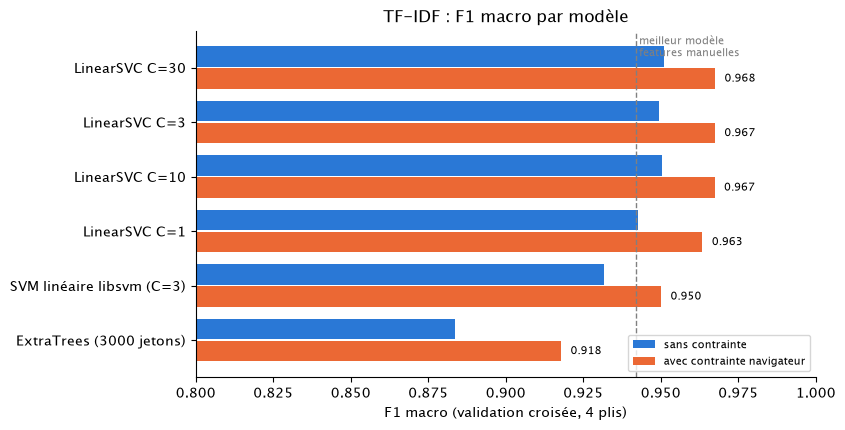

In [13]:
t = tableau.drop(index=[n for n in tableau.index if n.startswith("LinearSVC C=3 [")]).sort_values("F1 macro (contrainte)")
pos = np.arange(len(t))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(pos + 0.2, t["F1 macro"], height=0.38, color="#2a78d6", label="sans contrainte")
ax.barh(pos - 0.2, t["F1 macro (contrainte)"], height=0.38, color="#eb6834", label="avec contrainte navigateur")
for p, v in zip(pos, t["F1 macro (contrainte)"]):
    ax.text(v + 0.003, p - 0.2, f"{v:.3f}", va="center", fontsize=8)
ax.axvline(0.942, color="gray", ls="--", lw=1, label="meilleur modèle, features manuelles (0.942)")
ax.set_yticks(pos, t.index)
ax.set_xlim(0.8, 1)
ax.set_xlabel("F1 macro (validation croisée, 4 plis)")
ax.set_title("TF-IDF : F1 macro par modèle")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=3, fontsize=8, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
os.makedirs("images", exist_ok=True)
fig.savefig("images/fig_comparaison_tfidf.png", dpi=200, bbox_inches="tight")  # figure du rapport
plt.show()

**Lecture**
- **LinearSVC est le meilleur**, et dépasse nettement les features manuelles. Le score plafonne dès `C=3` : au-delà, +0,001 à +0,002, sous le seuil de fiabilité. Les analyses ci-dessous utilisent `C=3` ; la soumission finale utilise `C=30`, le meilleur en validation. Les deux obtiennent le même score sur Kaggle (0,988).
- **Les arbres se perdent** dans les colonnes creuses, même après sélection de 3000 jetons ; ils restent le meilleur choix sur les features manuelles (notebook 2).
- **Un contre tous plutôt qu'un contre un** : libsvm fait moins bien que LinearSVC (0,932 contre 0,949 sans contrainte) ; chacun de ses classifieurs ne voit que deux utilisateurs.
- **La contrainte navigateur aide tous les modèles**, l'ExtraTrees le plus (+0,034), LinearSVC et libsvm d'environ 0,018 : aucun n'exploite seul la règle « un utilisateur, un navigateur ». Sur les features manuelles du notebook 2, au contraire, elle ne change rien (testé à part) : l'ExtraTrees y reçoit le navigateur en one-hot, une colonne qu'il peut couper directement, et ne prédit jamais un utilisateur d'un autre navigateur. La comparaison 0,942 contre 0,967 est donc équitable.

### Ce que corrige la contrainte (LinearSVC C=3)

In [14]:
scores = scores_oof["LinearSVC C=3"]
libre, contraint = scores.argmax(axis=1), appliquer_contrainte(scores, train["navigateur"])
print("erreurs sans contrainte            :", (libre != y).sum())
print("  dont utilisateur d'un autre nav. :", (nav_classe[libre] != train["navigateur"]).sum())
print("erreurs avec contrainte            :", (contraint != y).sum())

erreurs sans contrainte            : 132
  dont utilisateur d'un autre nav. : 66
erreurs avec contrainte            : 92


### Erreurs selon la longueur de la session (LinearSVC C=3 + contrainte)

In [15]:
pd.Series(contraint != y).groupby(pd.qcut(train["nb_actions"], 5), observed=True).mean().round(3).rename("taux d'erreur")

nb_actions
(12.999, 131.0]     0.078
(131.0, 250.0]      0.029
(250.0, 484.0]      0.023
(484.0, 997.0]      0.008
(997.0, 11977.0]    0.003
Name: taux d'erreur, dtype: float64

- Les sessions courtes restent les plus difficiles, mais le taux d'erreur y est nettement plus faible qu'avec l'ExtraTrees du notebook 2 (7,8 % contre 11,4 % pour les plus courtes).

### Faut-il retirer les sessions extrêmes ?

On ne garde dans le train que les sessions d'au moins 10 actions (cf. `1_exploration`). Test des autres choix possibles : retirer les sessions très longues (règle de Tukey sur l'échelle brute) ou rapides (plus de 2 actions/s) **des plis d'entraînement seulement**, puis évaluer sur toutes les sessions (LinearSVC `C=3` + contrainte).

In [16]:
# On retire des sessions des plis d'entraînement seulement, puis on évalue sur toutes les sessions
q1, q3 = train["nb_actions"].quantile([.25, .75])
longues = (train["nb_actions"] > q3 + 1.5 * (q3 - q1)).to_numpy()            # Tukey sur l'échelle brute
rapides = (train["nb_actions"] / train["duree"].replace(0, np.nan) > 2).to_numpy()
variantes = {"tout garder (choix retenu)": np.zeros(len(y), dtype=bool), "sans les sessions longues": longues,
             "sans les sessions rapides": rapides, "sans les deux": longues | rapides}

lignes = {}
for nom, retirer in variantes.items():
    scores = np.full((len(y), K), -np.inf)
    for tr, va in skf.split(docs_train, y):
        tr = tr[~retirer[tr]]
        m = make_pipeline(vectoriseur(), LinearSVC(C=3)).fit([docs_train[i] for i in tr], y[tr])
        scores[va] = scores_classes(m, [docs_train[i] for i in va])
    preds = appliquer_contrainte(scores, train["navigateur"])
    lignes[nom] = {"sessions retirées du train": int(retirer.sum()), "accuracy": accuracy_score(y, preds),
                   "F1 macro": f1_score(y, preds, average="macro"),
                   "accuracy (sessions longues)": accuracy_score(y[longues], preds[longues]),
                   "accuracy (sessions rapides)": accuracy_score(y[rapides], preds[rapides])}
pd.DataFrame(lignes).T.round(3)

,sessions retirées du train,accuracy,F1 macro,accuracy (sessions longues),accuracy (sessions rapides)
tout garder (choix retenu),0.0,0.972,0.967,0.997,0.98
sans les sessions longues,297.0,0.964,0.951,0.963,0.98
sans les sessions rapides,50.0,0.971,0.966,0.997,0.96
sans les deux,343.0,0.964,0.949,0.963,0.98


- **Retirer les sessions longues coûte cher** : −0,016 de F1, bien au-delà du bruit (~0,005). Le modèle reconnaît ces sessions à 99,7 % quand il les a vues à l'entraînement, à 96,3 % sinon, et l'accuracy globale baisse aussi (0,972 → 0,964) : ce sont les sessions les plus riches en information.
- **Retirer les sessions rapides ne change rien** (−0,001) : une seule session de plus est mal reconnue.
- Garder toutes les sessions est donc le bon choix.

### Jetons les plus influents

Le modèle est un poids par jeton et par utilisateur : les plus gros poids positifs forment la « signature » d'un utilisateur. LinearSVC `C=3` entraîné sur tout le train :

In [17]:
svm = make_pipeline(vectoriseur(), LinearSVC(C=3)).fit(docs_train, y)
noms_jetons = svm[0].get_feature_names_out()
pd.DataFrame({u: [noms_jetons[j][:70] for j in np.argsort(svm[-1].coef_[classes.get_loc(u)])[::-1][:5]]
              for u in ["slq", "skm", "flj"]})

,slq,skm,flj
0,Affichage d'une dialogue(fr.infologic.core.cli...,C=ADM_055,C=LERCNAT
1,Affichage d'une dialogue(fr.infologic.core.cli...,Raccourci(fr.infologic.compta.client.modules.s...,C=EV_BK
2,Création d'un écran(infologic.core.gui.control...,Raccourci(fr.infologic.compta.client.modules.s...,T2=Saisie dans un champ >> Raccourci dans l'éd...
3,Exécution d'un bouton(fr.infologic.compta.clie...,Action de table1 >> Lancement d'une action gén...,Saisie dans un champ1 >> Raccourci dans l'édit...
4,Exécution d'un bouton(fr.infologic.global.clie...,Raccourci1 >> Raccourci dans l'édition de table1,Création d'un écran(infologic.core.gui.control...


- Les signatures mélangent configurations, actions sur des écrans précis et enchaînements : « où » et « comment ».
- Une décision résulte de nombreux petits indices ; aucun n'est décisif seul.

## 8. Limites
- La contrainte suppose qu'aucun utilisateur ne change de navigateur entre train et test (vrai à 100 % sur le train ; le score Kaggle suggère qu'elle tient).
- `C` et les jetons ont été choisis sur la validation croisée qui les évalue : score un peu optimiste, écarts de moins de 0,005 non fiables.
- Le score Kaggle (0,988) dépasse la validation croisée (0,967 à 0,968) : en validation, chaque utilisateur n'a qu'environ 10 sessions d'entraînement au lieu de 13 (explication probable, non vérifiée).

## 9. Soumission

Choisir le modèle par son nom dans le tableau ci-dessus, avec ou sans contrainte : il est réentraîné sur tout le train, puis prédit le test.

In [21]:
MODELE_SOUMISSION = "LinearSVC C=30"   # un nom parmi : list(modeles)
CONTRAINTE_NAVIGATEUR = True

assert MODELE_SOUMISSION in modeles, f"modèle inconnu, choisir parmi {list(modeles)}"
modele, jetons = modeles[MODELE_SOUMISSION]
d_train, d_test = documents[jetons]
scores_test = scores_classes(clone(modele).fit(d_train, y), d_test)
preds_test = appliquer_contrainte(scores_test, test["navigateur"]) if CONTRAINTE_NAVIGATEUR else scores_test.argmax(axis=1)
print("prédictions modifiées par la contrainte :", (preds_test != scores_test.argmax(axis=1)).sum())

nom = unicodedata.normalize("NFKD", MODELE_SOUMISSION).encode("ascii", "ignore").decode().lower()
nom = re.sub(r"[^a-z0-9]+", "_", nom).strip("_") + ("_navigateur" if CONTRAINTE_NAVIGATEUR else "")
chemin = f"submissions/tfidf_{nom}.csv"
os.makedirs("submissions", exist_ok=True)
soumission = pd.DataFrame({"prediction": classes[preds_test]}, index=pd.RangeIndex(1, len(test) + 1, name="RowId"))
soumission.to_csv(chemin)
print(f"{MODELE_SOUMISSION} → {chemin}")
soumission.head()

prédictions modifiées par la contrainte : 5
LinearSVC C=30 → submissions/tfidf_linearsvc_c_30_navigateur.csv


,prediction
RowId,
1,hzx
2,prb
3,jmq
4,psg
5,cvw
